# Code and data for *"Information-geometry-driven graph sequential growth"*

---

# Part 2: Fully-synthetic examples  

## Contents
 - [A. Problem setting](#sec2A)
 - [B. Experiment - Case $\eta=0.25$ (Section 6.2, Figure 6)](#sec2B)
 - [C. Experiment - Case $\eta=1$ (Section 6.2, Figure 7)](#sec2C)

<a id="sec2A"></a>
## A. Problem setting   

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

import all_solvers as sol
import all_experiments as exp

### Definition of the sparsity patterns 

Below, we generate the matrices $\mathbf{B}$ corresponding to the four considered sparsity patterns.  

1. Random with $m=200$.
2. Random with $m=40$.
3. Clique ($m=225$).
4. Hub ($m=45$). 

#### 1. Random with $m=200$  

In [2]:
rng = np.random.default_rng(seed=1)
## Set dimension
dim = 50
## Indices of the strict upper triangle (i < j) ; k=1 excludes the diagonal
iu, ju = np.triu_indices(dim, k=1)

## Set number of edges
m = 200 
## Randomly choose m positions among the strict upper triangle (without replacement)
sel = rng.choice(len(iu), size=m, replace=False)
## Create the matrix A
A = np.zeros((dim,dim))
A[iu[sel], ju[sel]] = rng.choice([-1, 1], m) * rng.uniform(0.5, 1.5, m)
## Symmetrised
A[ju[sel], iu[sel]] = A[iu[sel], ju[sel]]

## Populate diagonal of B with semidefinite programming
diag_val = cp.Variable(dim, nonneg=True)
prob = cp.Problem(cp.Minimize(cp.sum(diag_val)), [A + cp.diag(diag_val) >> 0])
prob.solve(solver=cp.SCS)   
# Create matrix B
B_r200 = A + np.diag(diag_val.value)

#### 2. Random with $m=40$

In [3]:
rng = np.random.default_rng(seed=1)
## Set dimension
dim = 50
# Indices of the strict upper triangle (i < j) ; k=1 excludes the diagonal
iu, ju = np.triu_indices(dim, k=1) 

## Set number of edges
m = 40 
## Randomly choose m positions among the strict upper triangle (without replacement)
sel = rng.choice(len(iu), size=m, replace=False)
## Create the matrix A
A = np.zeros((dim,dim))
A[iu[sel], ju[sel]] = rng.choice([-1, 1], m) * rng.uniform(0.5, 1.5, m)
## Symmetrized
A[ju[sel], iu[sel]] = A[iu[sel], ju[sel]]

## Populate diagonal of B with semidefinite programming
diag_val = cp.Variable(dim, nonneg=True)
prob = cp.Problem(cp.Minimize(cp.sum(diag_val)), [A + cp.diag(diag_val) >> 0])
prob.solve(solver=cp.SCS)   
## Create matrix B
B_r40 = A + np.diag(diag_val.value)

#### 3. Clique

In [4]:
rng = np.random.default_rng(seed=1)
## Set dimension
dim = 50
## Indices of the strict upper triangle (i < j) ; k=1 excludes the diagonal
iu, ju = np.triu_indices(dim, k=1) 

## Set number of blocks (should be a divisor of dim)
n_block = 5
block_size = dim // n_block
## Keep only indices (i, j) that lie in the same block
same_block = (iu // block_size) == (ju // block_size)
iu_block = iu[same_block]
ju_block = ju[same_block]
## Populate matrix B
A = np.zeros((dim,dim))
m = len(iu_block)
A[iu_block, ju_block] = rng.choice([-1, 1], m) * rng.uniform(0.5, 1.5, m)
A[ju_block, iu_block] = A[iu_block, ju_block]

## Populate diagonal of B with semidefinite programming
diag_val = cp.Variable(dim, nonneg=True)
prob = cp.Problem(cp.Minimize(cp.sum(diag_val)), [A + cp.diag(diag_val) >> 0])
prob.solve(solver=cp.SCS)   
## Create matrix B
B_cli = A + np.diag(diag_val.value)

#### 4. Hub

In [5]:
rng = np.random.default_rng(seed=1)
## Set dimension
dim = 50
## Indices of the strict upper triangle (i < j) ; k=1 excludes the diagonal
iu, ju = np.triu_indices(dim, k=1) 

## Set number of hubs (should be a divisor of dim)
n_hub = 5
hub_size = dim // n_hub
## Define hub structure
boundaries = np.arange(1, n_hub+1) * hub_size - 1
ju_hub = np.repeat(boundaries, hub_size - 1)
## iu_hub: all indices except the last in each block
starts = np.arange(0, dim, hub_size)  #
iu_hub = np.concatenate([np.arange(s, s + hub_size - 1) for s in starts])

## Populate matrix B
A = np.zeros((dim,dim))
m = len(iu_hub)
A[iu_hub, ju_hub] = rng.choice([-1, 1], m) * rng.uniform(0.5, 1.5, m)
A[ju_hub, iu_hub] = A[iu_hub, ju_hub]

## Populate diagonal of B with semidefinite programming
diag_val = cp.Variable(dim, nonneg=True)
prob = cp.Problem(cp.Minimize(cp.sum(diag_val)), [A + cp.diag(diag_val) >> 0])
prob.solve(solver=cp.SCS)   
# Create matrix B
B_hub = A + np.diag(diag_val.value)

#### Graphical representation of the sparsity patterns

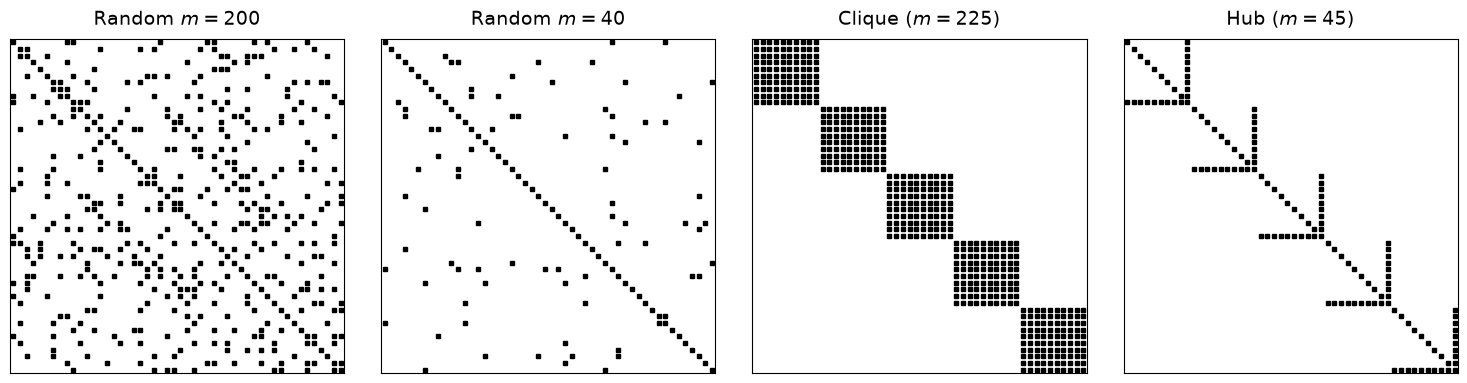

In [6]:
## Plot sparsity patterns 
fig, axes = plt.subplots(1, 4, figsize=(15, 3.75))
plt.rcParams.update({"text.usetex": True, "text.latex.preamble": r"\usepackage{amsmath}"})
ax = axes[0]
ax.spy(B_r200 + np.eye(dim), markersize=3, color='black')
ax.set_title(rf"Random $m=200$", fontsize=14, pad=10)
ax.set_xticks([]) ; ax.set_yticks([])

ax = axes[1]
ax.spy(B_r40 + np.eye(dim), markersize=3, color='black')
ax.set_title(rf"Random $m=40$", fontsize=14, pad=10)
ax.set_xticks([]) ; ax.set_yticks([])

ax = axes[2]
ax.spy(B_cli + np.eye(dim), markersize=3, color='black')
ax.set_title(rf"Clique $(m=225)$", fontsize=14, pad=10)
ax.set_xticks([]) ; ax.set_yticks([])

ax = axes[3]
ax.spy(B_hub + np.eye(dim), markersize=3, color='black')
ax.set_title(rf"Hub $(m=45)$", fontsize=14, pad=10)
ax.set_xticks([]) ; ax.set_yticks([])

plt.tight_layout()
plt.show()

<a id="sec2B"></a>
## B. Experiment - Case $\eta=0.25$ (Section 6.2, Figure 6)

Below, we generate the matrices $\boldsymbol{\Sigma}$ and $\boldsymbol{\Theta}$ for each of the four considered sparsity patterns, in the case $\eta=0.25$.  

In [7]:
## Form true covariance and precision from matrix B
def matB_to_cov(B, eta):
    dim = B.shape[0]
    C = B + eta * np.eye(dim) 
    inv_C = np.linalg.inv(C)
    # Cov to Corr to define true covariance
    sqrt_diag_XX = np.sqrt(np.diag(inv_C))
    true_cov = inv_C / np.outer(sqrt_diag_XX, sqrt_diag_XX) # is a correlation
    true_prec = C * np.outer(sqrt_diag_XX, sqrt_diag_XX)
    return true_cov, true_prec

In [8]:
## Define true covariance and precision   
eta = 0.25
true_cov_r200_e025, true_prec_r200_e025 = matB_to_cov(B_r200, eta)
true_cov_r40_e025, true_prec_r40_e025 = matB_to_cov(B_r40, eta)
true_cov_cli_e025, true_prec_cli_e025 = matB_to_cov(B_cli, eta)
true_cov_hub_e025, true_prec_hub_e025 = matB_to_cov(B_hub, eta)

We now proceed with the experiments (computation of Monte Carlo ROC and precision-recall profiles for each of the four covariance matrices, and each time for three different sample sizes).

> **Computational note:** Numerically, and for similar approximate-full-correction parameters, computing a BFCI growth is significantly more demanding than computing a GS, GSL or BBI growth. Experiments involving multiple full BFCI growths are relatively demanding (for $d=50$, each full BFCI growth can take a few minutes). To run a ROC-curve experiment without BFCI, remove `BFCI` from the `methods` input list of the function `run_experiment_ROC`.  

### 1. Random with $m=200$ ($\eta=0.25$)

In [9]:
## 1. Run experiment 
## Each BFCI run can take a few minutes
results_r200_e025 = exp.run_experiment_ROC(
    true_cov=true_cov_r200_e025,
    true_P=true_prec_r200_e025,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    n_reps_BFCI=10,
    #methods=['Prec', 'PCorr', 'Glasso', 'BFCI', 'BBI', 'GSL'], 
    methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'],           # run without BFCI 
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500, 
    RP_coeff=1e-6,
    n_jobs=-1, # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [01:08<00:00,  1.46it/s]


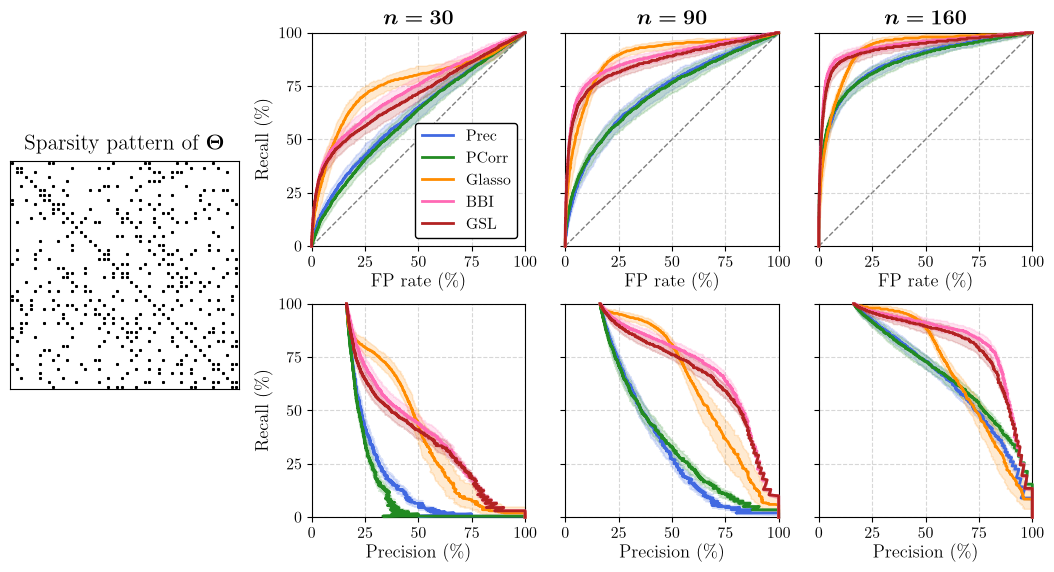

In [10]:
## 2. ROC and precision-recall curves
fig = exp.plot_figure_1(
    results=results_r200_e025,
    true_P=true_prec_r200_e025,
    n_samples_list=[30, 90, 160]
)

### 2. Random with $m=40$ ($\eta=0.25$)

In [11]:
## 1. Run experiment 
results_r40_e025 = exp.run_experiment_ROC(
    true_cov=true_cov_r40_e025,
    true_P=true_prec_r40_e025,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    n_reps_BFCI=10,
    #methods=['Prec', 'PCorr', 'Glasso', 'BFCI', 'BBI', 'GSL'], 
    methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'],           # run without BFCI
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500, 
    RP_coeff=1e-6,
    n_jobs=-1, # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [00:58<00:00,  1.72it/s]


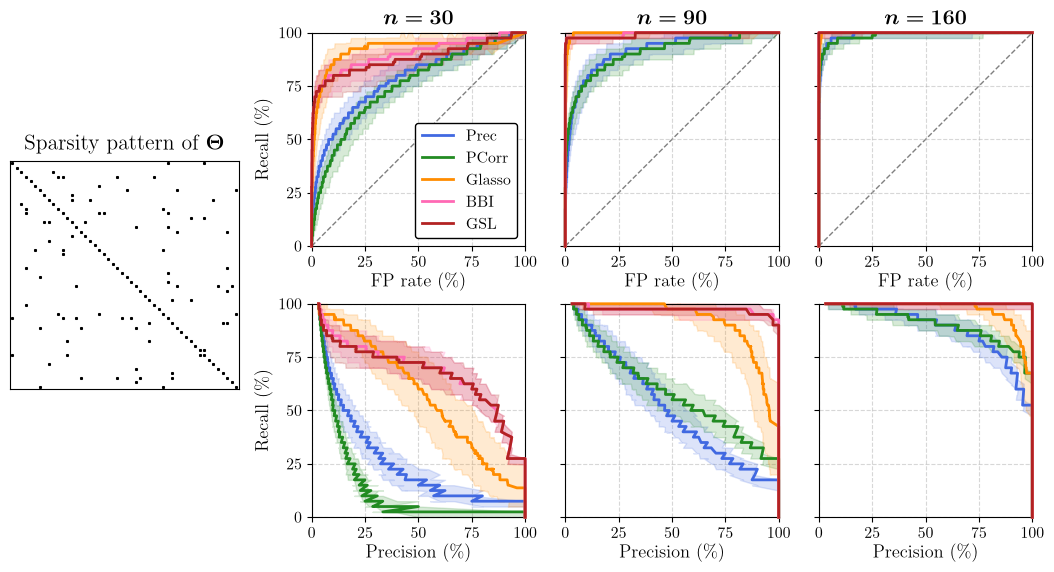

In [12]:
## 2. ROC and precision-recall curves
fig = exp.plot_figure_1(
    results=results_r40_e025,
    true_P=true_prec_r40_e025,
    n_samples_list=[30, 90, 160]
)

### 3. Clique ($\eta=0.25$)

In [13]:
## 1. Run experiment 
results_cli_e025 = exp.run_experiment_ROC(
    true_cov=true_cov_cli_e025,
    true_P=true_prec_cli_e025,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    n_reps_BFCI=10,
    #methods=['Prec', 'PCorr', 'Glasso', 'BFCI', 'BBI', 'GSL'], 
    methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'],           # run without BFCI
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500, 
    RP_coeff=1e-6,
    n_jobs=-1, # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [01:09<00:00,  1.43it/s]


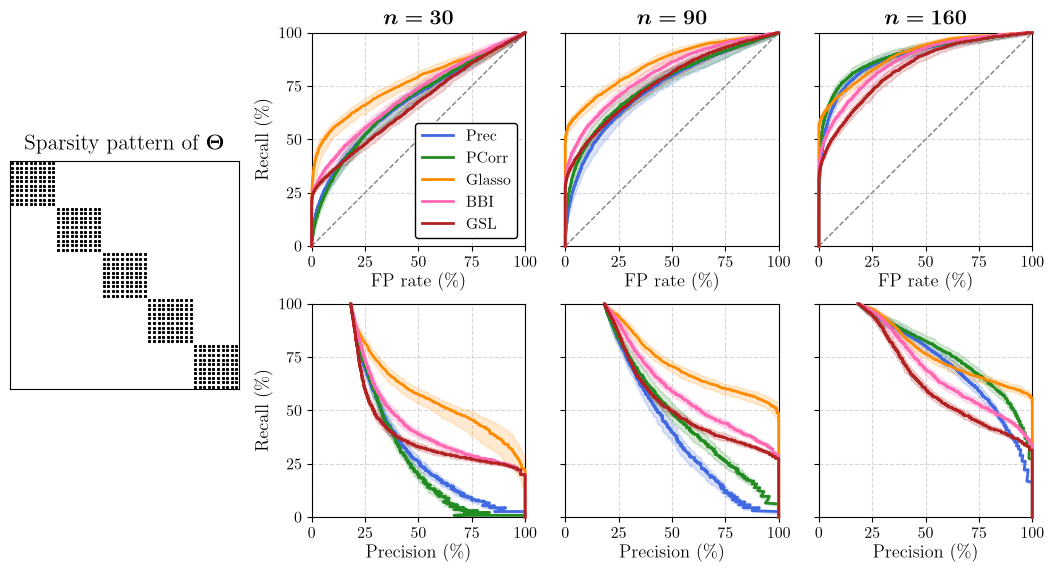

In [14]:
## 2. ROC and precision-recall curves
fig = exp.plot_figure_1(
    results=results_cli_e025,
    true_P=true_prec_cli_e025,
    n_samples_list=[30, 90, 160]
)

### 4. Hub ($\eta=0.25$)

In [15]:
## 1. Run experiment 
results_hub_e025 = exp.run_experiment_ROC(
    true_cov=true_cov_hub_e025,
    true_P=true_prec_hub_e025,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    n_reps_BFCI=10,
    #methods=['Prec', 'PCorr', 'Glasso', 'BFCI', 'BBI', 'GSL'], 
    methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'],           # run without BFCI
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500, 
    RP_coeff=1e-6,
    n_jobs=-1, # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [01:04<00:00,  1.55it/s]


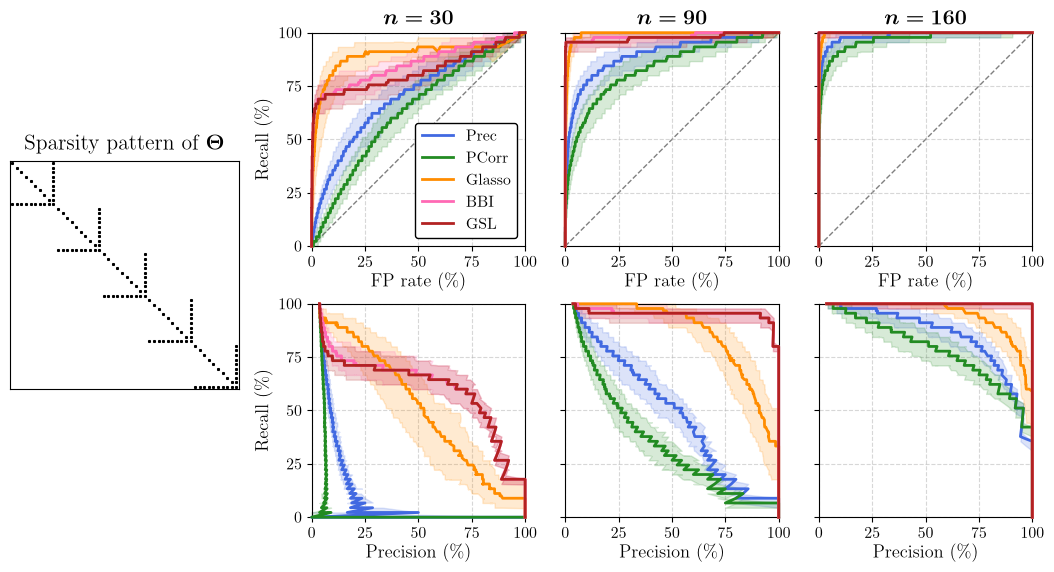

In [16]:
## 2. ROC and precision-recall curves
fig = exp.plot_figure_1(
    results=results_hub_e025,
    true_P=true_prec_hub_e025,
    n_samples_list=[30, 90, 160]
)

### Render Figure 6

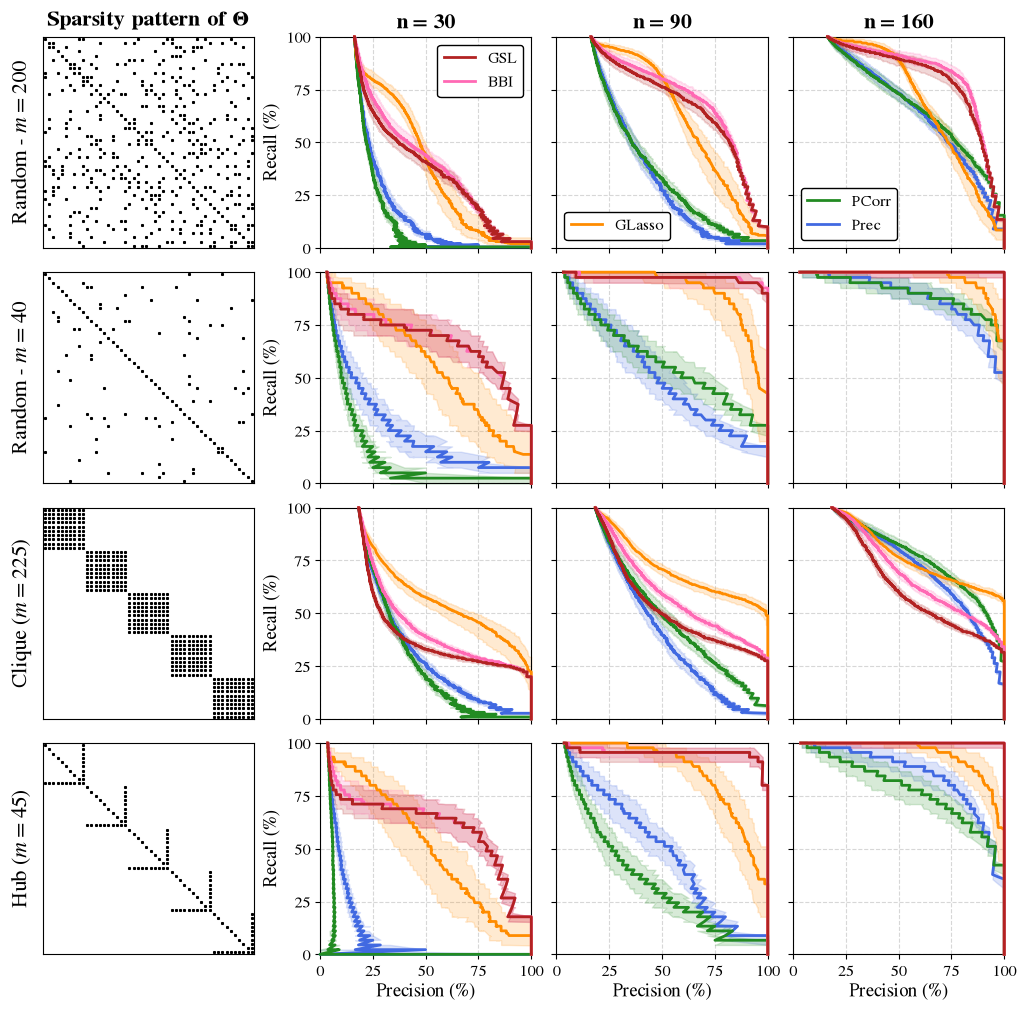

In [17]:
## Assemble experiment configurations
experiments_data_fig6 = [
    {'name': r"Random - $m=200$", 'true_P': true_prec_r200_e025, 'results': results_r200_e025},
    {'name': r"Random - $m=40$",  'true_P': true_prec_r40_e025,  'results': results_r40_e025},
    {'name': r"Clique ($m=225$)", 'true_P': true_prec_cli_e025,  'results': results_cli_e025},
    {'name': r"Hub ($m=45$)",    'true_P': true_prec_hub_e025,  'results': results_hub_e025},
]

## Render Figure 6 
fig6 = exp.plot_figure_6(
    experiments_data=experiments_data_fig6,
    n_samples_list=[30, 90, 160],
    font_scale=1.2,
    inter_dec=True, 
    glasso_legend='bottom'
    #save_path="Figures/Figure_6.pdf"
)

<a id="sec2C"></a>
## C. Experiment - Case $\eta=1$ (Section 6.2, Figure 7)

Below, we generate the matrices $\boldsymbol{\Sigma}$ and $\boldsymbol{\Theta}$ for each of the four considered sparsity patterns, in the case $\eta=1$.  

In [18]:
## Define true covariance and precision   
eta = 1
true_cov_r200_e1, true_prec_r200_e1 = matB_to_cov(B_r200, eta)
true_cov_r40_e1, true_prec_r40_e1 = matB_to_cov(B_r40, eta)
true_cov_cli_e1, true_prec_cli_e1 = matB_to_cov(B_cli, eta)
true_cov_hub_e1, true_prec_hub_e1 = matB_to_cov(B_hub, eta)

We now proceed with the experiments (computation of Monte Carlo ROC and precision-recall profiles for each of the four covariance matrices, and each time for three different sample sizes). 

### 1. Random with $m=200$ ($\eta=1$)

In [19]:
## 1. Run experiment 
results_r200_e1 = exp.run_experiment_ROC(
    true_cov=true_cov_r200_e1,
    true_P=true_prec_r200_e1,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    n_reps_BFCI=10,
    #methods=['Prec', 'PCorr', 'Glasso', 'BFCI', 'BBI', 'GSL'], 
    methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'],           # run without BFCI
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500, 
    RP_coeff=1e-6,
    n_jobs=-1, # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [00:56<00:00,  1.78it/s]


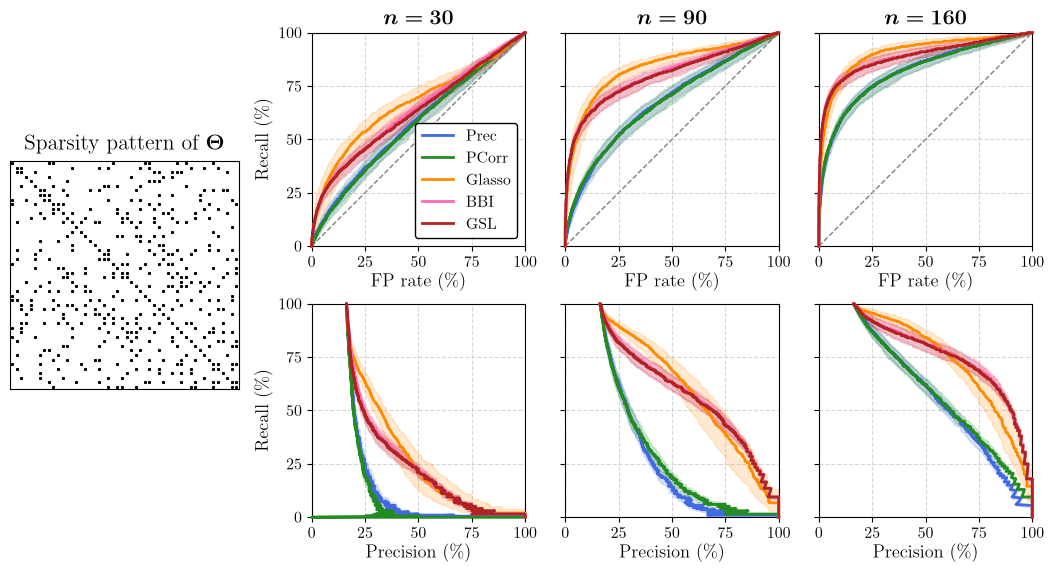

In [20]:
## 2. ROC and precision-recall curves
fig = exp.plot_figure_1(
    results=results_r200_e1,
    true_P=true_prec_r200_e1,
    n_samples_list=[30, 90, 160]
)

### 2. Random with $m=40$ ($\eta=1$)

In [21]:
## 1. Run experiment 
results_r40_e1 = exp.run_experiment_ROC(
    true_cov=true_cov_r40_e1,
    true_P=true_prec_r40_e1,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    n_reps_BFCI=10,
    #methods=['Prec', 'PCorr', 'Glasso', 'BFCI', 'BBI', 'GSL'], 
    methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'],           # run without BFCI
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500, 
    RP_coeff=1e-6,
    n_jobs=-1, # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [00:44<00:00,  2.23it/s]


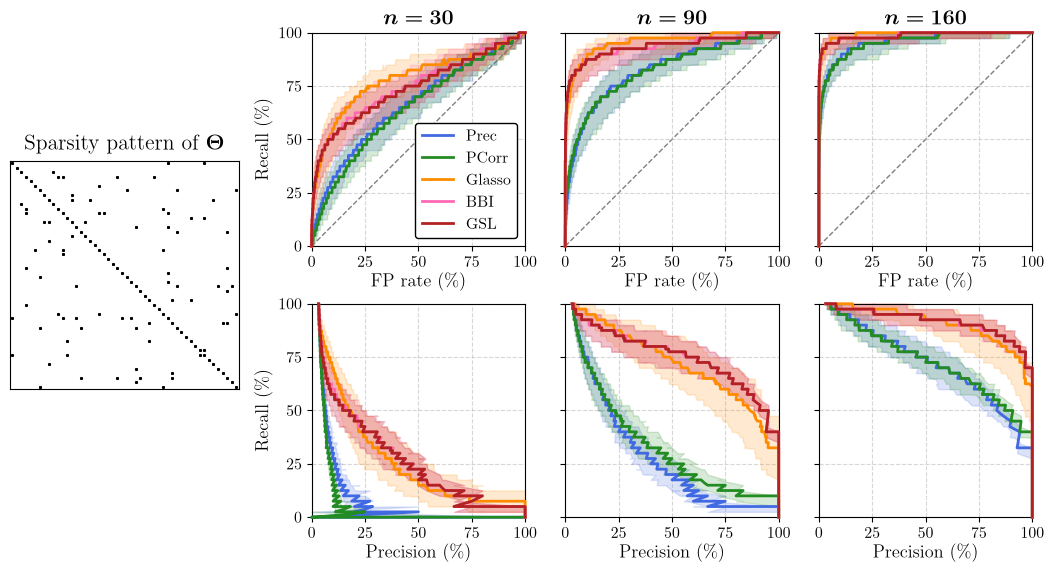

In [22]:
## 2. ROC and precision-recall curves
fig = exp.plot_figure_1(
    results=results_r40_e1,
    true_P=true_prec_r40_e1,
    n_samples_list=[30, 90, 160]
)

### 3. Clique ($\eta=1$)

In [23]:
## 1. Run experiment 
results_cli_e1 = exp.run_experiment_ROC(
    true_cov=true_cov_cli_e1,
    true_P=true_prec_cli_e1,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    n_reps_BFCI=10,
    #methods=['Prec', 'PCorr', 'Glasso', 'BFCI', 'BBI', 'GSL'], 
    methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'],           # run without BFCI
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500, 
    RP_coeff=1e-6,
    n_jobs=-1, # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [00:57<00:00,  1.75it/s]


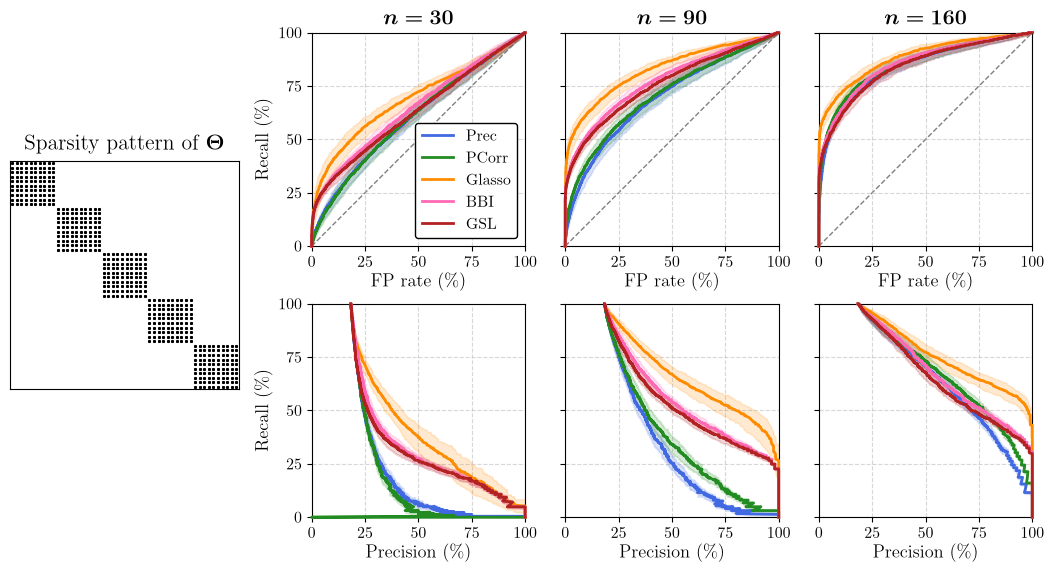

In [24]:
## 2. ROC and precision-recall curves
fig = exp.plot_figure_1(
    results=results_cli_e1,
    true_P=true_prec_cli_e1,
    n_samples_list=[30, 90, 160]
)

### 4. Hub ($\eta=1$)

In [25]:
## 1. Run experiment 
results_hub_e1 = exp.run_experiment_ROC(
    true_cov=true_cov_hub_e1,
    true_P=true_prec_hub_e1,
    n_samples_list=[30, 90, 160],
    n_reps=100,
    n_reps_BFCI=10,
    #methods=['Prec', 'PCorr', 'Glasso', 'BFCI', 'BBI', 'GSL'], 
    methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'],           # run without BFCI
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    n_glasso=500, 
    RP_coeff=1e-6,
    n_jobs=-1, # allocate maximum number of threads
    seed=1
)

Starting parallel ROC experiment: d=50, reps=100, 
methods=['Prec', 'PCorr', 'Glasso', 'BBI', 'GSL'], n_jobs=-1


Sample size n = 160: 100%|███████████████████| 100/100 [00:44<00:00,  2.25it/s]


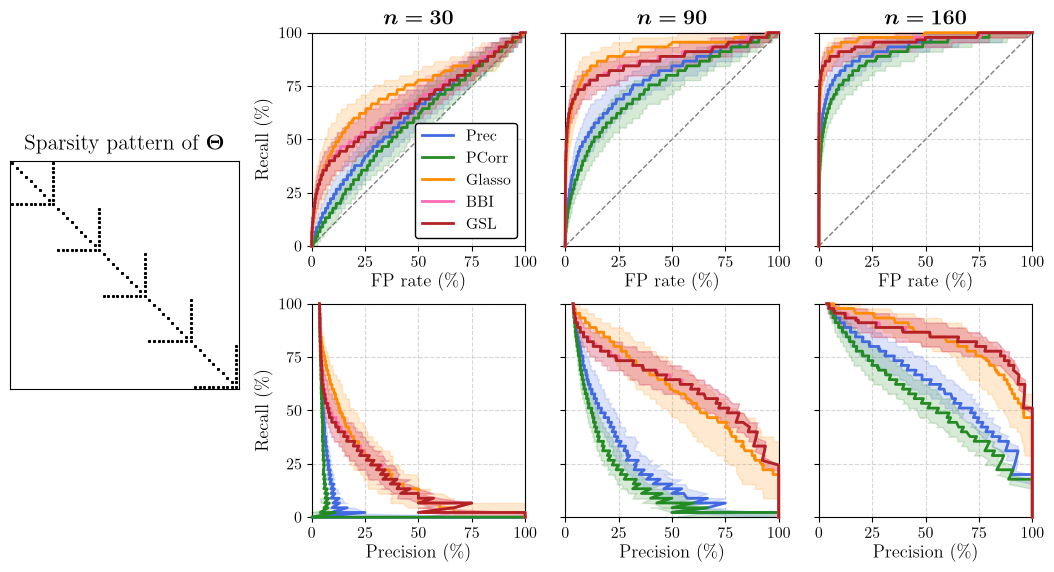

In [26]:
## 2. ROC and precision-recall curves
fig = exp.plot_figure_1(
    results=results_hub_e1,
    true_P=true_prec_hub_e1,
    n_samples_list=[30, 90, 160]
)

### Render Figure 7

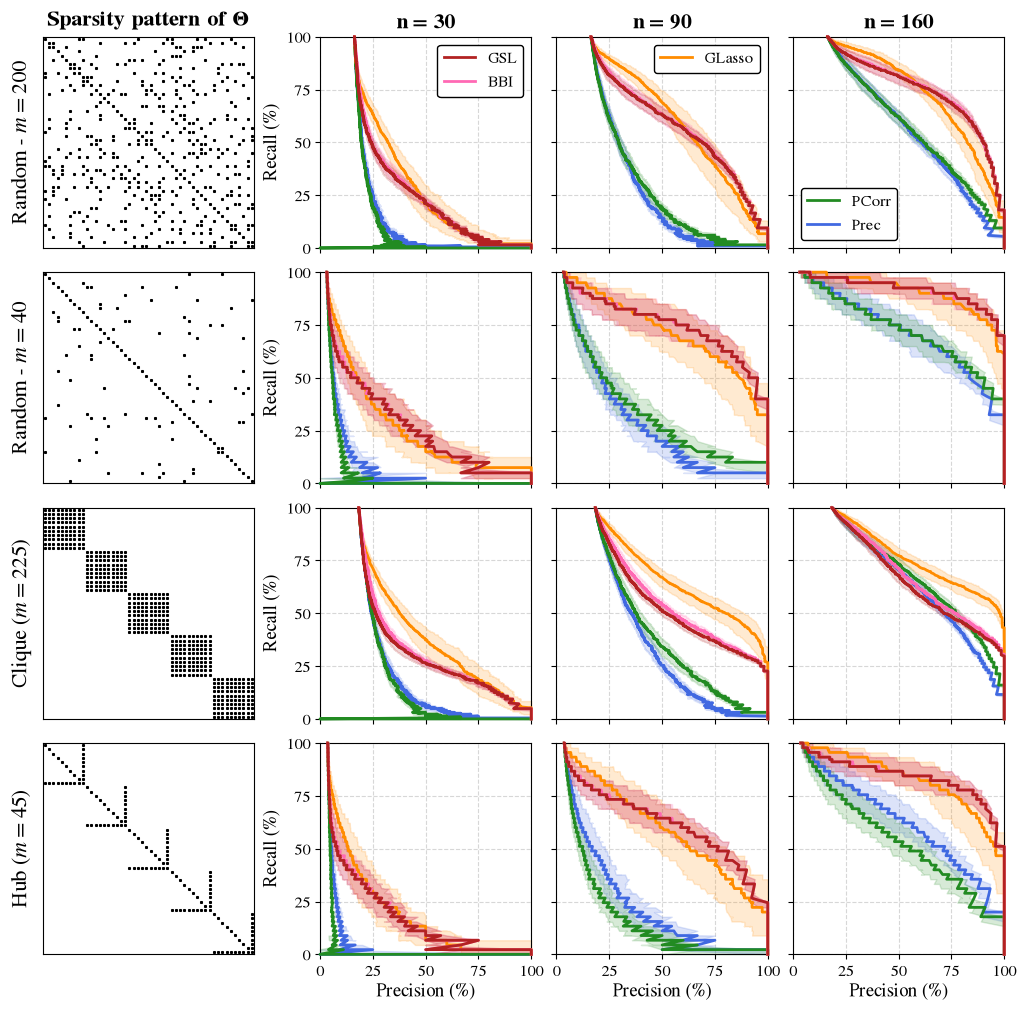

In [27]:
## 1. Assemble experiment configurations
experiments_data_fig7 = [
    {'name': r"Random - $m=200$", 'true_P': true_prec_r200_e1, 'results': results_r200_e1},
    {'name': r"Random - $m=40$",  'true_P': true_prec_r40_e1,  'results': results_r40_e1},
    {'name': r"Clique ($m=225$)", 'true_P': true_prec_cli_e1,  'results': results_cli_e1},
    {'name': r"Hub ($m=45$)",    'true_P': true_prec_hub_e1,  'results': results_hub_e1},
]

## 2. Render Figure 7 
fig7 = exp.plot_figure_6(
    experiments_data=experiments_data_fig7,
    n_samples_list=[30, 90, 160],
    font_scale=1.2,
    inter_dec=True,
    glasso_legend='top'
    #save_path="Figures/Figure_7.pdf"
)